We will learn how to tell a data story with a small sales dataset.
First, we will set the purpose and audience.
Then, we will tell the story using simple charts.
After that, we will do a practical activity so everyone can apply the same steps.

Dataset, Mini Superstore, columns are Region, Product, Sales, Profit.
Goal, find which region and product drive profit.
Audience, a manager who wants quick and clear insights.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

candidates = [
    Path("mini_superstore_sales.csv"),
    Path("/content/mini_superstore_sales.csv"),
]
file_path = next((p for p in candidates if p.exists()), None)
if file_path is None:
    raise FileNotFoundError("Put mini_superstore_sales.csv next to this notebook.")

df = pd.read_csv(file_path)

print("Rows and columns:", df.shape)
print(df.dtypes)
df.head()


# Tell the story, executive **KPIs**

In [3]:
print("Story part, executive view")

total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
profit_margin = total_profit / total_sales
total_rows = len(df)
regions = df["Region"].nunique()
products = df["Product"].nunique()

kpis = pd.DataFrame({
    "Metric": ["Total Sales", "Total Profit", "Profit Margin", "Rows", "Regions", "Products"],
    "Value": [total_sales, total_profit, profit_margin, total_rows, regions, products]
})

print(kpis.to_string(index=False))

Story part, executive view
       Metric         Value
  Total Sales 151390.000000
 Total Profit   6628.370000
Profit Margin      0.043783
         Rows    150.000000
      Regions      4.000000
     Products      6.000000


# **Story By Region**

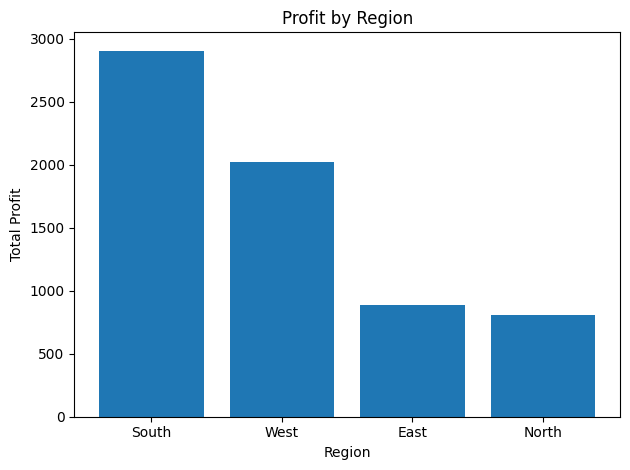

,Region,Profit
2,South,2906.94
3,West,2025.56
0,East,886.01
1,North,809.86


In [ ]:

region_profit = (df.groupby("Region", as_index=False)["Profit"]
                   .sum()
                   .sort_values("Profit", ascending=False))

plt.figure()
plt.bar(region_profit["Region"], region_profit["Profit"])
plt.title("Profit by Region")
plt.xlabel("Region")
plt.ylabel("Total Profit")
plt.tight_layout()
plt.show()

region_profit

# Tell the story, profit by product

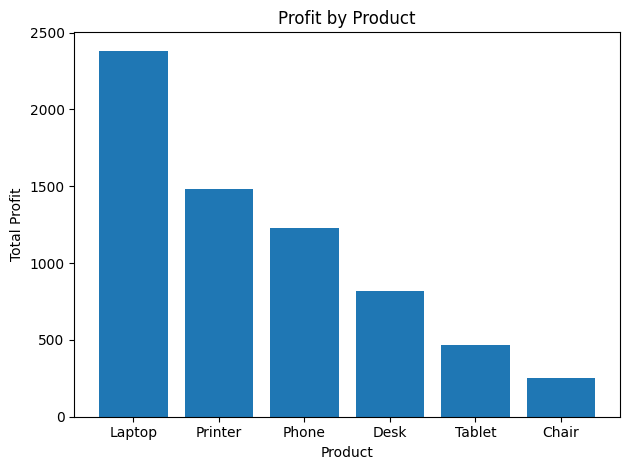

,Product,Profit
2,Laptop,2382.43
4,Printer,1481.95
3,Phone,1230.53
1,Desk,815.98
5,Tablet,467.30
0,Chair,250.18


In [4]:


product_profit = (df.groupby("Product", as_index=False)["Profit"]
                    .sum()
                    .sort_values("Profit", ascending=False))

plt.figure()
plt.bar(product_profit["Product"], product_profit["Profit"])
plt.title("Profit by Product")
plt.xlabel("Product")
plt.ylabel("Total Profit")
plt.tight_layout()
plt.show()

product_profit

**region by product pivot**

In [5]:


pivot_profit = df.pivot_table(index="Region", columns="Product", values="Profit",
                              aggfunc="sum", fill_value=0)
pivot_profit

Product,Chair,Desk,Laptop,Phone,Printer,Tablet
Region,,,,,,
East,-103.70,151.48,278.44,510.41,192.42,-143.04
North,368.00,-207.95,678.06,-76.56,217.36,-169.05
South,-291.67,-156.03,1002.90,734.09,921.72,695.93
West,277.55,1028.48,423.03,62.59,150.45,83.46


# sales and profit together in one scatter

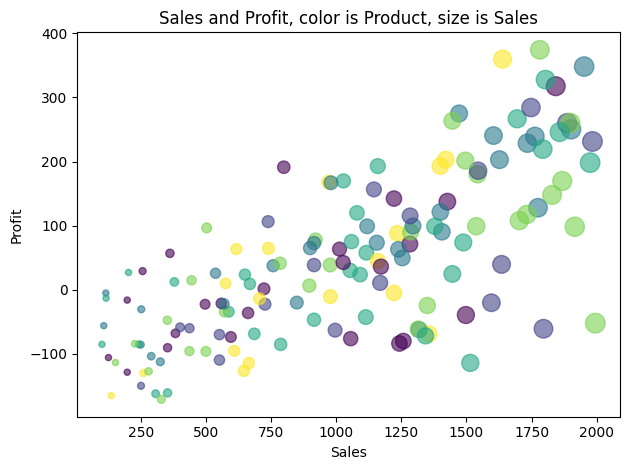

In [ ]:

plot_df = df.dropna(subset=["Sales", "Profit", "Product"]).copy()
plot_df["ProdCode"] = plot_df["Product"].astype("category").cat.codes
sizes = np.clip(plot_df["Sales"] * 0.1, 20, 300)

plt.figure()
plt.scatter(plot_df["Sales"], plot_df["Profit"], c=plot_df["ProdCode"], s=sizes, alpha=0.6)
plt.title("Sales and Profit, color is Product, size is Sales")
plt.xlabel("Sales")
plt.ylabel("Profit")
plt.tight_layout()
plt.show()






# Pick a slice of the data, for example one region.
# Make two charts that support a clear message



Summary for region, East
Product  Sales  Profit    Margin
  Phone   6411  510.41  0.079615
 Laptop   5324  278.44  0.052299
Printer   7340  192.42  0.026215
   Desk   4662  151.48  0.032492
  Chair   4590 -103.70 -0.022593
 Tablet   4319 -143.04 -0.033119


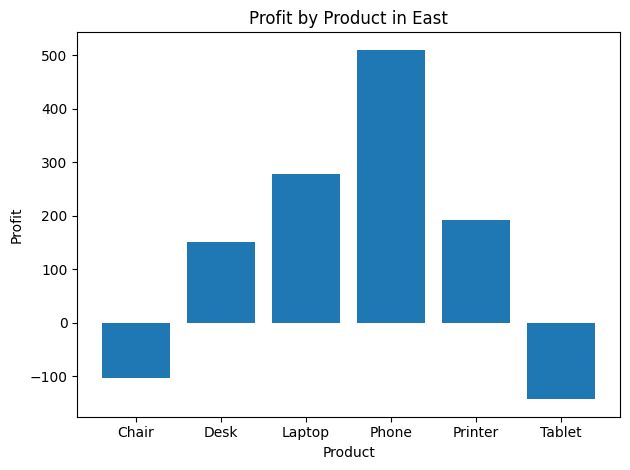

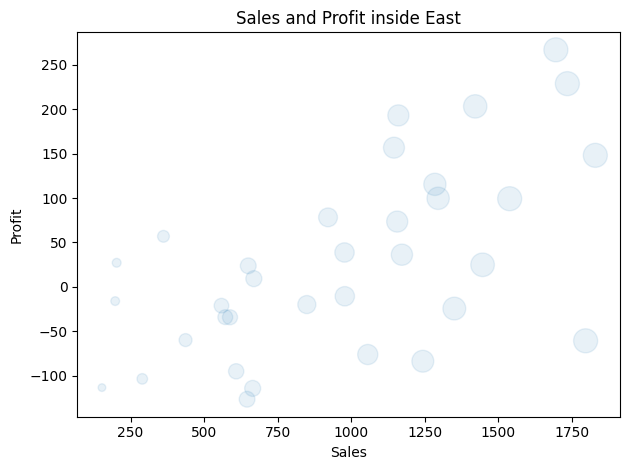


Short narrative
Audience, regional manager
Region, East
Message, which products drive profit, which need attention
Finding, top product by profit is at the top of the bar chart
Finding, some rows show high sales but weak profit, consider price or cost review


In [6]:
chosen_region = "East"

slice_df = df[df["Region"] == chosen_region].copy()

summary = (slice_df.groupby("Product", as_index=False)
           .agg(Sales=("Sales", "sum"), Profit=("Profit", "sum")))
summary["Margin"] = summary["Profit"] / summary["Sales"]

print(f"Summary for region, {chosen_region}")
print(summary.sort_values("Profit", ascending=False).to_string(index=False))

plt.figure()
plt.bar(summary["Product"], summary["Profit"])
plt.title(f"Profit by Product in {chosen_region}")
plt.xlabel("Product")
plt.ylabel("Profit")
plt.tight_layout()
plt.show()

sizes = np.clip(slice_df["Sales"] * 0.2, 20, 300)
plt.figure()
plt.scatter(slice_df["Sales"], slice_df["Profit"], s=sizes, alpha=0.1)
plt.title(f"Sales and Profit inside {chosen_region}")
plt.xlabel("Sales")
plt.ylabel("Profit")
plt.tight_layout()
plt.show()

print("\nShort narrative")
print("Audience, regional manager")
print(f"Region, {chosen_region}")
print("Message, which products drive profit, which need attention")
print("Finding, top product by profit is at the top of the bar chart")
print("Finding, some rows show high sales but weak profit")


# **CEO view**

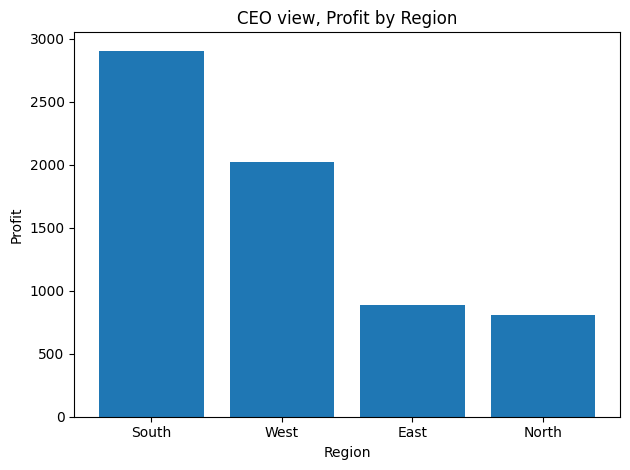

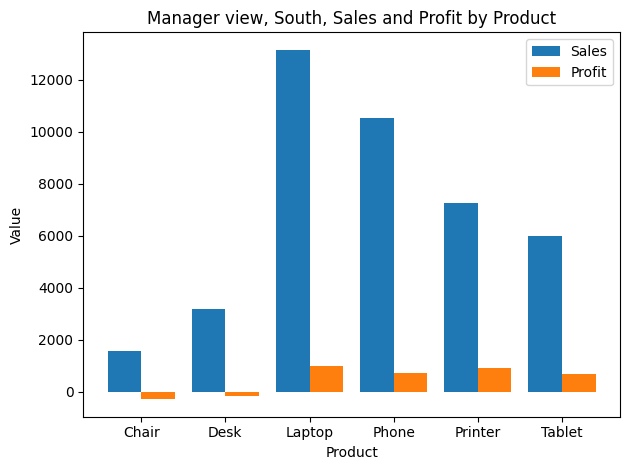

In [7]:

ceo_view = df.groupby("Region", as_index=False)["Profit"].sum().sort_values("Profit", ascending=False)

plt.figure()
plt.bar(ceo_view["Region"], ceo_view["Profit"])
plt.title("CEO view, Profit by Region")
plt.xlabel("Region")
plt.ylabel("Profit")
plt.tight_layout()
plt.show()

best_region = ceo_view.iloc[0]["Region"]
mgr = df[df["Region"] == best_region].groupby("Product", as_index=False)[["Sales", "Profit"]].sum()

x = np.arange(len(mgr))
w = 0.4

plt.figure()
plt.bar(x - 0.2, mgr["Sales"], width=w, label="Sales")
plt.bar(x + 0.2, mgr["Profit"], width=w, label="Profit")
plt.title(f"Manager view, {best_region}, Sales and Profit by Product")
plt.xlabel("Product")
plt.ylabel("Value")
plt.xticks(x, mgr["Product"])
plt.legend()
plt.tight_layout()
plt.show()


Summary for region, East
Product  Sales  Profit    Margin
  Phone   6411  510.41  0.079615
 Laptop   5324  278.44  0.052299
Printer   7340  192.42  0.026215
   Desk   4662  151.48  0.032492
  Chair   4590 -103.70 -0.022593
 Tablet   4319 -143.04 -0.033119


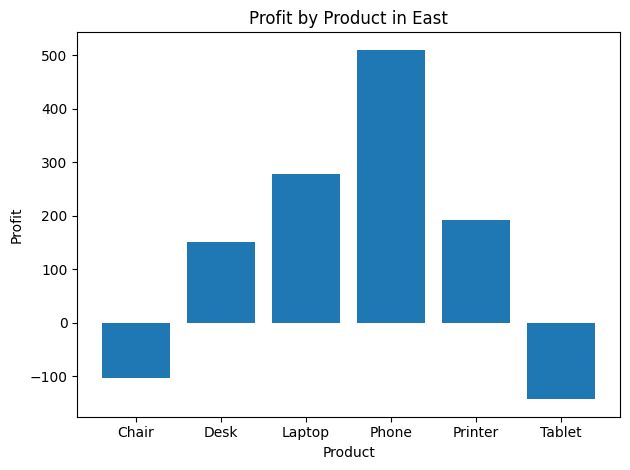

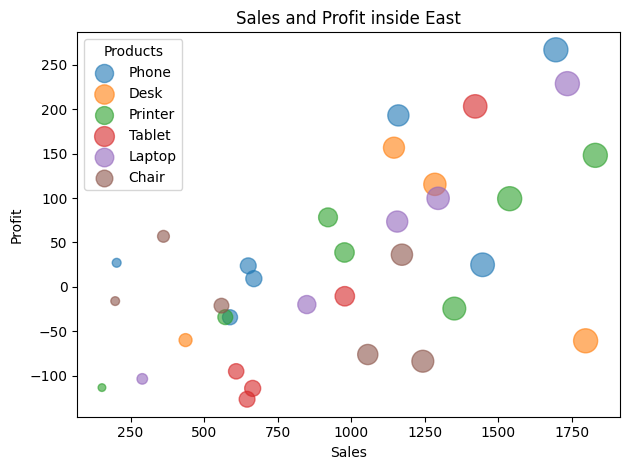

In [8]:
chosen_region = "East"

slice_df = df[df["Region"] == chosen_region].copy()

summary = (slice_df.groupby("Product", as_index=False)
           .agg(Sales=("Sales", "sum"), Profit=("Profit", "sum")))
summary["Margin"] = summary["Profit"] / summary["Sales"]

print(f"Summary for region, {chosen_region}")
print(summary.sort_values("Profit", ascending=False).to_string(index=False))


plt.figure()
plt.bar(summary["Product"], summary["Profit"])
plt.title(f"Profit by Product in {chosen_region}")
plt.xlabel("Product")
plt.ylabel("Profit")
plt.tight_layout()
plt.show()


sizes = np.clip(slice_df["Sales"] * 0.2, 20, 300)


colors = slice_df["Product"].astype("category").cat.codes  # tell python to give each product a color


plt.figure()

for product in slice_df["Product"].unique():
    data = slice_df[slice_df["Product"] == product]
    sizes = np.clip(data["Sales"] * 0.2, 20, 300)
    plt.scatter(data["Sales"], data["Profit"],
                s=sizes, alpha=0.6, label=product)

plt.title(f"Sales and Profit inside {chosen_region}")
plt.xlabel("Sales")
plt.ylabel("Profit")
plt.legend(title="Products")
plt.tight_layout()
plt.show()


#print("\nShort narrative")
#print("Audience, regional manager")
#print(f"Region, {chosen_region}")
#print("Message, which products drive profit, which need attention")
#print("Finding, top product by profit is at the top of the bar chart")
#print("Finding, some rows show high sales but weak profit")


# Three findings

Same file: 150 rows, columns Region, Product, Sales, Profit. Each finding is a different cut.


In [ ]:
region = (
    df.groupby("Region", as_index=False)
      .agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"), Rows=("Sales", "count"))
)
region["Margin_%"] = region["Profit"] / region["Sales"] * 100
region = region.sort_values("Profit", ascending=False)

pair = df.pivot_table(index="Region", columns="Product", values="Profit", aggfunc="sum")
sign = pair.apply(lambda col: ((col > 0).sum(), (col < 0).sum()))

df = df.copy()
df["Sales_band"] = pd.qcut(df["Sales"], 4)
band = df.groupby("Sales_band", observed=True)["Profit"].sum()

print(region.round(1).to_string(index=False))
print()
print(pair.round(0).astype(int).to_string())
print()
print(band.round(0).astype(int).to_string())


## 1. The sales leader is not the profit leader

West has the highest sales, 47,531, and profit of 2,026 (margin 4.3%).
South has sales of 41,762 and profit of 2,907 (margin 7.0%).

A sales ranking picks West. A profit ranking picks South. This is the chart for a sales manager: the bar is margin, and sales stays on the label so the extra volume is still visible.


In [ ]:
story = region.sort_values("Margin_%", ascending=True)
colours = {"South": "#0B6E4F", "West": "#C2410C", "East": "#C5CAD3", "North": "#C5CAD3"}
overall = df["Profit"].sum() / df["Sales"].sum() * 100

fig, ax = plt.subplots(figsize=(8.2, 3.8))
ax.barh(story["Region"], story["Margin_%"], color=[colours[r] for r in story["Region"]], height=0.62)
ax.axvline(overall, color="#1F2933", linestyle="--", linewidth=1)
ax.text(overall, len(story) - 0.55, f"all rows  {overall:.1f}%", ha="center", va="bottom", fontsize=8, color="#1F2933")

for y, (_, row) in enumerate(story.iterrows()):
    ax.text(row["Margin_%"] + 0.12, y, f"{row['Margin_%']:.1f}%    sales {row['Sales']:,.0f}", va="center", fontsize=9, color="#1F2933")

ax.set_xlim(0, story["Margin_%"].max() + 3.4)
ax.set_ylim(-0.5, len(story) - 0.15)
ax.set_xlabel("Profit / sales (%)")
ax.set_title("West leads on sales. South leads on margin.", loc="left")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(length=0)
plt.tight_layout()
plt.show()


## 2. The same product changes sign by region

Laptop and Printer are profitable in all four regions. Chair, Desk, and Tablet are profitable in two and loss-making in two.

The totals hide the flip. West desks are +1,028. North desks are −208. South tablets are +696. East and North tablets are both negative. A product manager needs the pairs, not the product total.


In [ ]:
from matplotlib.colors import TwoSlopeNorm

region_order = ["South", "West", "East", "North"]
product_order = ["Laptop", "Printer", "Phone", "Desk", "Tablet", "Chair"]
grid = pair.loc[region_order, product_order]

fig, ax = plt.subplots(figsize=(8.6, 3.5))
norm = TwoSlopeNorm(vmin=grid.values.min(), vcenter=0, vmax=grid.values.max())
im = ax.imshow(grid.values, cmap="RdBu", norm=norm, aspect="auto")

ax.set_xticks(range(len(product_order)))
ax.set_xticklabels(product_order)
ax.set_yticks(range(len(region_order)))
ax.set_yticklabels(region_order)

for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        value = grid.values[i, j]
        ink = "white" if abs(value) > 280 else "#1F2933"
        ax.text(j, i, f"{value:,.0f}", ha="center", va="center", color=ink, fontsize=8)

ax.set_title("Same product, opposite profit, depending on the region.", loc="left")
ax.tick_params(length=0)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Profit")
plt.tight_layout()
plt.show()


## 3. The smallest sales band loses money in every cut

The 38 rows with sales from 101 to 552 lose 2,540 together. That loss shows up in every region and in every product. 31 of those 38 rows are negative.

The 38 rows with sales from 1,446 to 1,995 make 6,683. Separately, 63 of 150 rows are negative, and those rows are 28% of all sales (42,170 of 151,390).

Small sales are not a harmless tail. They reduce profit whichever way the file is split.


In [ ]:
bands = (
    df.groupby("Sales_band", observed=True)
      .agg(Sales_min=("Sales", "min"), Sales_max=("Sales", "max"), Profit=("Profit", "sum"), Rows=("Sales", "count"))
)
labels = [f"{int(row.Sales_min)}–{int(row.Sales_max)}" for row in bands.itertuples()]
colours = ["#C2410C", "#C5CAD3", "#C5CAD3", "#0B6E4F"]

fig, ax = plt.subplots(figsize=(7.4, 3.6))
bars = ax.bar(labels, bands["Profit"], color=colours, width=0.72)
ax.axhline(0, color="#1F2933", linewidth=0.8)

for bar, value in zip(bars, bands["Profit"]):
    offset = 180 if value >= 0 else -180
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + offset,
        f"{value:,.0f}",
        ha="center",
        va="bottom" if value >= 0 else "top",
        fontsize=9,
        color="#1F2933",
    )

ax.set_ylabel("Total profit")
ax.set_xlabel("Sales in the band")
ax.set_title("The smallest sales band loses 2,540. The largest makes 6,683.", loc="left")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(length=0)
ax.set_ylim(bands["Profit"].min() - 1200, bands["Profit"].max() + 900)
plt.tight_layout()
plt.show()


## Who sees which chart

Do not show all three as one picture.

- Sales manager: chart 1. The question is whether the sales league table is the right target.
- Product manager: chart 2. The question is which region–product pairs lose money. Laptop and Printer do not. The red cells do.
- Both: chart 3. The small-sales loss is in every region and every product, so it is not a local exception.

**Say this.** West sells the most and South keeps more. A product that makes money in one region can lose it in another. Rows with sales under 552 lose money across the whole file. Compare regions on profit, manage products as region pairs, and review the small-sales rows before adding more of them.

**Five-second test.** Cover the prose and show one chart. The other person should be able to repeat that chart's title. If they cannot, the title is doing too little and the colour is doing too much, or the other way round.
